# Searching for hidden companions around MoM-BH\*-1

*A separate test, not used in the research note in this repository (see the README).*

**Why:** the direct-collapse test (`direct_collapse_test_MoM-BH1.ipynb`) shows that the big neighbour at 64 kpc gives 16–1,600 times too little Lyman–Werner light for direct collapse. A *smaller* galaxy much closer could still do it, because UV light gets weaker with the square of the distance. At MoM-BH\*-1's distance, **1 arcsecond ≈ 5 kpc**, so we search the JWST images within about 3 arcseconds.

**How to recognise a real companion** at the same redshift (z = 7.76):
1. It should show up in the **UV filters F115W, F150W and F200W** (rest frame about 1,300–2,300 Å).
2. It should be **almost invisible in F090W.** At this redshift, everything bluer than Lyman-α (observed at 1.07 µm) is absorbed by neutral hydrogen between the galaxies and us. This "dropout" test separates true companions from nearer, foreground galaxies.

**The plan:** download the images, check the calibration against the paper, look at the images, find sources near the black hole star, and work out their UV light (J21). Then set a limit on anything too faint to see.

**How to use:** run the grey code cells from top to bottom with **Shift + Enter**.

*Images: JWST PRIMER survey (GO-1837), processed by the DAWN JWST Archive (DJA) with grizli.*

## Step 1 — Download image cutouts from the DAWN JWST Archive

This asks the DJA cutout server for small images (about 6–13 arcseconds across) around MoM-BH\*-1 in seven NIRCam filters. The server builds them on request, so it can take **about a minute**. It also installs **photutils**, which Colab doesn't have by default.

In [1]:
!pip install -q photutils

import os, urllib.request
RA, DEC = 34.3974841, -5.1351163          # MoM-BH*-1, from the paper
FILTERS = ["f090w-clear", "f115w-clear", "f150w-clear", "f200w-clear",
           "f277w-clear", "f356w-clear", "f444w-clear"]
url = ("https://grizli-cutout.herokuapp.com/thumb?"
       f"ra={RA}&dec={DEC}&size=8&filters={','.join(FILTERS)}&output=fits_weight")

print("Asking the DJA server for image cutouts (this can take a minute)...")
urllib.request.urlretrieve(url, "mom_bh1_cutouts.fits")
size_mb = os.path.getsize("mom_bh1_cutouts.fits") / 1e6
print(f"Downloaded {size_mb:.1f} MB")
if size_mb < 0.05:
    print("That's too small to be images. The server replied:")
    print(open("mom_bh1_cutouts.fits", errors="ignore").read()[:500])

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 9.4 MB/s eta 0:00:00
Asking the DJA server for image cutouts (this can take a minute)...
Downloaded 5.9 MB


## Step 2 — Open the images

The file has one image per filter, plus a "weight" image for each that we don't need. The cell converts every image to **nJy per pixel** using the calibration number stored in its header (PHOTFNU). It then prints what it found.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.wcs import WCS
from astropy.wcs.utils import proj_plane_pixel_scales
from astropy.coordinates import SkyCoord
from astropy.cosmology import Planck18
from astropy import units as u

Z = 7.7569
KPC_PER_ARCSEC = Planck18.kpc_proper_per_arcmin(Z).to(u.kpc / u.arcsec).value
target = SkyCoord(RA * u.deg, DEC * u.deg)

images = {}
with fits.open("mom_bh1_cutouts.fits") as hdul:
    for hdu in hdul:
        if hdu.data is None or hdu.data.ndim != 2:
            continue
        filt = str(hdu.header.get("FILTER", hdu.header.get("EXTNAME", "?"))).upper().split("-")[0]
        if "WHT" in str(hdu.header.get("EXTVER", "")).upper() or filt in images:
            continue                                      # skip weight images
        photfnu = hdu.header.get("PHOTFNU", 0) or 0       # Jy per pixel unit
        wcs = WCS(hdu.header)
        images[filt] = dict(
            nJy=np.nan_to_num(hdu.data.astype(float)) * (photfnu * 1e9 if photfnu > 0 else 10.0),
            wcs=wcs,
            pixscale=proj_plane_pixel_scales(wcs)[0] * 3600,
            calib="PHOTFNU from header" if photfnu > 0 else "ASSUMED 10 nJy per unit",
        )

print(f"1 arcsec = {KPC_PER_ARCSEC:.2f} kpc at z = {Z}\n")
for filt, im in images.items():
    ny, nx = im["nJy"].shape
    print(f"{filt}: {nx}x{ny} pixels, {im['pixscale']:.3f}\"/pixel "
          f"({nx * im['pixscale']:.1f}\" wide), calibration: {im['calib']}")

1 arcsec = 5.02 kpc at z = 7.7569

F090W: 320x320 pixels, 0.050"/pixel (16.0" wide), calibration: PHOTFNU from header
F115W: 320x320 pixels, 0.050"/pixel (16.0" wide), calibration: PHOTFNU from header
F150W: 320x320 pixels, 0.050"/pixel (16.0" wide), calibration: PHOTFNU from header
F200W: 320x320 pixels, 0.050"/pixel (16.0" wide), calibration: PHOTFNU from header
F277W: 320x320 pixels, 0.050"/pixel (16.0" wide), calibration: PHOTFNU from header
F356W: 320x320 pixels, 0.050"/pixel (16.0" wide), calibration: PHOTFNU from header
F444W: 320x320 pixels, 0.050"/pixel (16.0" wide), calibration: PHOTFNU from header


## Step 3 — Check the calibration against the paper

Before trusting any numbers, measure something we already know. The paper's photometry table gives MoM-BH\*-1's F444W brightness as **243 ± 12 nJy** (Naidu et al. 2026a, Extended Data Table 2; the text rounds it to 25.4 mag), measured from these same images.

We measure it inside a circle of radius 0.3″. A small circle misses some light in the outer glow of the star-like image, so expect a ratio of **about 0.8–0.9**, not exactly 1.

In [3]:
from photutils.aperture import SkyCircularAperture, CircularAperture, aperture_photometry


def aperture_flux(filt, coord, radius_arcsec):
    '''Total nJy inside a circle of the given radius (arcsec) around a sky position.'''
    im = images[filt]
    ap = SkyCircularAperture(coord, r=radius_arcsec * u.arcsec).to_pixel(im["wcs"])
    return float(aperture_photometry(im["nJy"], ap)["aperture_sum"][0])


f444 = aperture_flux("F444W", target, 0.3)
ratio = f444 / 243
print(f"F444W inside 0.3\": {f444:.0f} nJy   (paper total: 243 nJy)   ratio = {ratio:.2f}")
if 0.6 < ratio < 1.1:
    print("Calibration looks right.")
else:
    print("Something's off with the units or the position. Paste this output before going further.")

F444W inside 0.3": 194 nJy   (paper total: 243 nJy)   ratio = 0.80
Calibration looks right.


## Step 4 — Look at the images

Each panel shows ±3″ around MoM-BH\*-1 (red +). The dashed ring is 1″ (5 kpc) and the dotted ring is 2″ (10 kpc).

What to expect:
- **MoM-BH\*-1 itself** should be invisible in F090W–F200W and appear in F277W–F444W. That's its giant Balmer break.
- **A real companion** would appear in F115W–F200W but vanish in F090W.
- **A foreground galaxy** would appear in F090W too.

The figure is saved as **MoM-BH1_companion_images.png**.

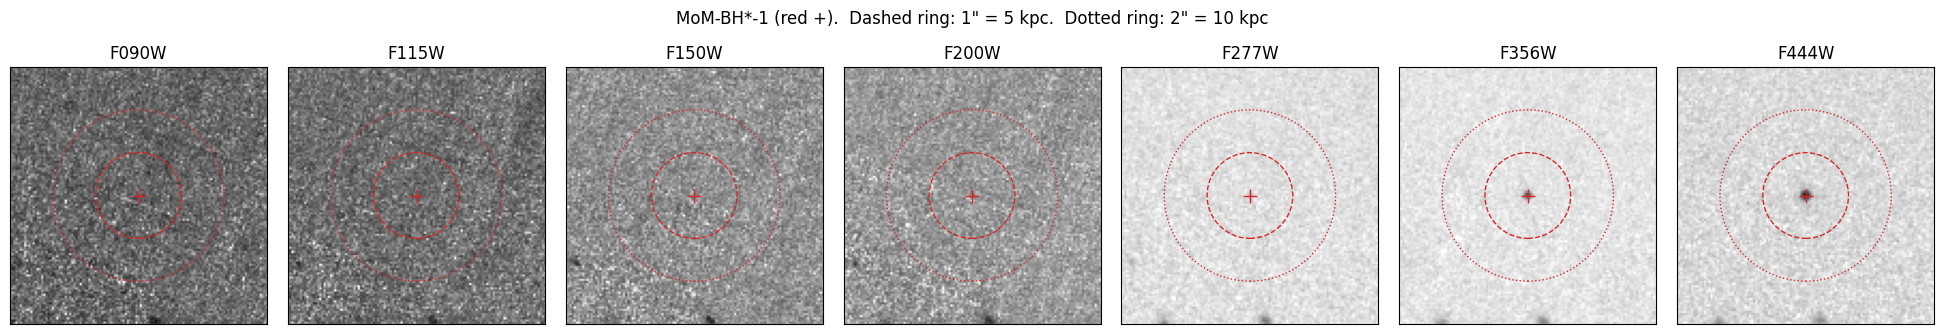

In [4]:
from astropy.visualization import simple_norm
from matplotlib.patches import Circle

order = [f for f in ["F090W", "F115W", "F150W", "F200W", "F277W", "F356W", "F444W"] if f in images]
fig, axes = plt.subplots(1, len(order), figsize=(2.8 * len(order), 3.2))
for ax, filt in zip(np.atleast_1d(axes), order):
    im = images[filt]
    x0, y0 = im["wcs"].world_to_pixel(target)
    half = 3.0 / im["pixscale"]                               # +/- 3 arcsec
    ax.imshow(im["nJy"], origin="lower", cmap="gray_r",
              norm=simple_norm(im["nJy"], "asinh", percent=99.5))
    ax.set_xlim(x0 - half, x0 + half)
    ax.set_ylim(y0 - half, y0 + half)
    for r_arcsec, ls in [(1, "--"), (2, ":")]:
        ax.add_patch(Circle((x0, y0), r_arcsec / im["pixscale"], fill=False, color="tab:red", ls=ls, lw=1))
    ax.plot(x0, y0, "+", color="tab:red", ms=10)
    ax.set_title(filt)
    ax.set_xticks([])
    ax.set_yticks([])
plt.suptitle('MoM-BH*-1 (red +).  Dashed ring: 1" = 5 kpc.  Dotted ring: 2" = 10 kpc', y=1.03)
plt.tight_layout()
fig.savefig("MoM-BH1_companion_images.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 5 — Measure the noise, then find sources near MoM-BH\*-1

**Noise:** we drop 500 circles (radius 0.2″) at random places in each image and measure the light inside each. Most land on empty sky, so the spread of their values is the realistic noise for one circle. Circles that happen to land on galaxies are thrown out automatically (sigma-clipping).

**Detection:** we average F115W, F150W and F200W into one deeper **UV image**, smooth it slightly, and find anything that stands out above the noise. For each source within 3″ of MoM-BH\*-1, the cell prints:
- its distance (arcsec and kpc);
- its signal-to-noise (S/N) in the UV and in F090W;
- a verdict: **companion?** (seen in UV, not in F090W), **foreground** (seen in F090W), or **unclear**;
- for possible companions, the **J21** it would give MoM-BH\*-1, using the projected distance (so it's a maximum).

In [5]:
from astropy.stats import sigma_clipped_stats
from astropy.convolution import Gaussian2DKernel, convolve
from photutils.segmentation import detect_sources, SourceCatalog

AP_R = 0.2                        # aperture radius, arcsec
rng = np.random.default_rng(1)
D_L = Planck18.luminosity_distance(Z)


def empty_aperture_noise(data, pixscale, n=500):
    '''Scatter of fluxes in randomly placed circles = realistic noise for one circle.'''
    r = AP_R / pixscale
    ny, nx = data.shape
    pos = np.transpose([rng.uniform(r + 1, nx - r - 1, n), rng.uniform(r + 1, ny - r - 1, n)])
    sums = np.array(aperture_photometry(data, CircularAperture(pos, r=r))["aperture_sum"])
    return sigma_clipped_stats(sums, sigma=3)[2]


def J21_from(flux_nJy, d_kpc):
    '''Lyman-Werner intensity (J21) at distance d_kpc from a z=7.76 source with this UV flux.'''
    L = 4 * np.pi * D_L**2 * (flux_nJy * u.nJy) / (1 + Z)
    J = L / (16 * np.pi**2 * (d_kpc * u.kpc) ** 2) / u.sr
    return (J / (1e-21 * u.erg / u.s / u.cm**2 / u.Hz / u.sr)).decompose().value


noise = {f: empty_aperture_noise(images[f]["nJy"], images[f]["pixscale"]) for f in images}
for f in images:
    print(f"{f}: noise in a {AP_R}\" circle = {noise[f]:.1f} nJy")

# average the UV filters (they share the same pixel grid) into one deeper image
uv_filters = [f for f in ["F115W", "F150W", "F200W"] if f in images]
uv_filters = [f for f in uv_filters if images[f]["nJy"].shape == images[uv_filters[0]]["nJy"].shape]
uv = np.mean([images[f]["nJy"] for f in uv_filters], axis=0)
uv_wcs, uv_pix = images[uv_filters[0]]["wcs"], images[uv_filters[0]]["pixscale"]
uv_noise = empty_aperture_noise(uv, uv_pix)
print(f"\nUV image ({'+'.join(uv_filters)}): noise = {uv_noise:.1f} nJy, "
      f"3-sigma limit = {3 * uv_noise:.1f} nJy ({31.4 - 2.5 * np.log10(3 * uv_noise):.1f} mag)")

# find sources in the smoothed UV image
smooth = convolve(uv, Gaussian2DKernel(1.5))
_, med, std = sigma_clipped_stats(smooth, sigma=3)
segm = detect_sources(smooth - med, 2.5 * std, 8)
cat = SourceCatalog(uv, segm, convolved_data=smooth) if segm is not None else []

# light right at the black hole star's own position (its host galaxy, if anything)
at_bh = np.mean([aperture_flux(f, target, AP_R) for f in uv_filters])
print(f"\nUV light at MoM-BH*-1's own position: {at_bh:.1f} nJy (S/N {at_bh / uv_noise:.1f})")

xs = getattr(cat, "x_centroid", None) if len(cat) else []
ys = getattr(cat, "y_centroid", None) if len(cat) else []
if len(cat) and xs is None:                      # older photutils versions
    xs, ys = cat.xcentroid, cat.ycentroid

print(f"\nSources detected (S/N >= 3) within 3\" of MoM-BH*-1:")
candidates = []
for x, y in zip(xs, ys):
    pos = uv_wcs.pixel_to_world(x, y)
    sep = pos.separation(target).arcsec
    if sep > 3.0 or sep < 0.3:                   # skip far sources and the black hole star's own position
        continue
    uv_flux = np.mean([aperture_flux(f, pos, AP_R) for f in uv_filters])
    sn_uv = uv_flux / uv_noise
    if sn_uv < 3:
        continue                                 # too faint to be a real detection
    f090 = aperture_flux("F090W", pos, AP_R) if "F090W" in images else np.nan
    ratio = f090 / uv_flux                       # ~0 for a z=7.76 companion, ~1 for most foreground galaxies
    if ratio < 0.3:
        verdict = "companion? (drops out in F090W)"
    elif ratio > 0.6 and f090 / noise["F090W"] >= 3:
        verdict = "foreground (bright in F090W)"
    else:
        verdict = "unclear"
    kpc = sep * KPC_PER_ARCSEC
    line = (f"  {sep:4.2f}\" ({kpc:4.1f} kpc)  UV {uv_flux:5.1f} nJy (S/N {sn_uv:5.1f})  "
            f"F090W/UV = {ratio:5.2f}  -> {verdict}")
    if not verdict.startswith("foreground"):
        J = J21_from(uv_flux, kpc)
        candidates.append((kpc, J, verdict))
        line += f"   J21 at MoM-BH*-1 <= {J:,.0f}"
    print(line)
if not candidates:
    print("  No possible companions: everything detected nearby is foreground (or nothing is detected).")

F090W: noise in a 0.2" circle = 7.9 nJy
F115W: noise in a 0.2" circle = 9.1 nJy
F150W: noise in a 0.2" circle = 6.2 nJy
F200W: noise in a 0.2" circle = 5.8 nJy
F277W: noise in a 0.2" circle = 3.4 nJy
F356W: noise in a 0.2" circle = 3.5 nJy
F444W: noise in a 0.2" circle = 4.1 nJy

UV image (F115W+F150W+F200W): noise = 4.9 nJy, 3-sigma limit = 14.6 nJy (28.5 mag)

UV light at MoM-BH*-1's own position: 3.4 nJy (S/N 0.7)

Sources detected (S/N >= 3) within 3" of MoM-BH*-1:
  2.98" (14.9 kpc)  UV  64.4 nJy (S/N  13.2)  F090W/UV =  1.00  -> foreground (bright in F090W)
  No possible companions: everything detected nearby is foreground (or nothing is detected).


## Step 6 — What about companions too faint to see?

No detection doesn't mean nothing is there, only that anything there is fainter than the images can show. We take the **3-sigma limit** of the UV image as the brightest a hidden companion could be. We then ask how close it would have to be to reach each direct-collapse threshold.

The plot shows:
- the J21 an *undetected* companion could give at each distance (black dashed line);
- any possible companions you found (red points);
- the big neighbour from the direct-collapse test (blue point);
- the range of theoretical thresholds (orange band).

The plot is saved as **MoM-BH1_companion_limits.png**.

Brightest a hidden companion could be (3 sigma): 14.6 nJy

threshold J21 =    100: a hidden companion could reach it only if closer than 9.1 kpc (1.82")
threshold J21 =  1,000: a hidden companion could reach it only if closer than 2.9 kpc (0.58")
threshold J21 = 10,000: a hidden companion could reach it only if closer than 0.9 kpc (0.18")


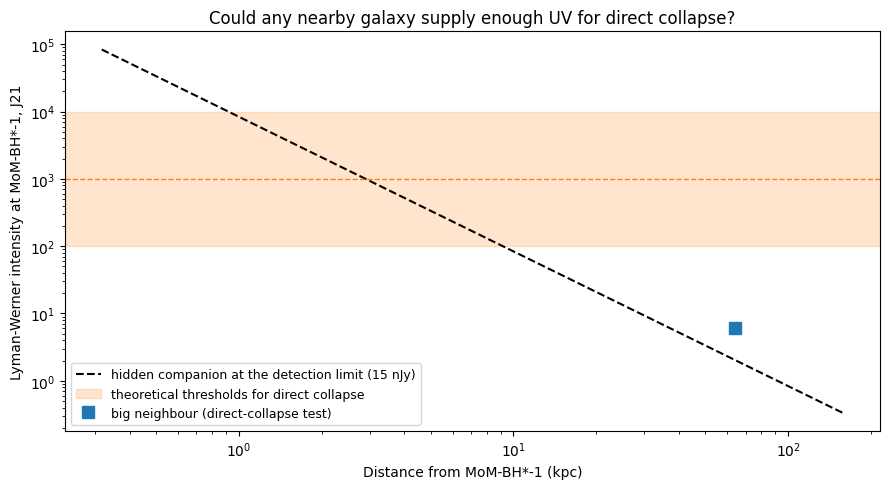

In [6]:
F_lim = 3 * uv_noise
print(f"Brightest a hidden companion could be (3 sigma): {F_lim:.1f} nJy\n")
for J_crit in [100, 1000, 10000]:
    d_max = np.sqrt(J21_from(F_lim, 1.0) / J_crit)        # J21 falls as 1/d^2
    print(f"threshold J21 = {J_crit:>6,}: a hidden companion could reach it only if closer than "
          f"{d_max:.1f} kpc ({d_max / KPC_PER_ARCSEC:.2f}\")")

d = np.logspace(-0.5, 2.2, 300)
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(d, J21_from(F_lim, d), "k--", label=f"hidden companion at the detection limit ({F_lim:.0f} nJy)")
ax.axhspan(100, 10000, color="tab:orange", alpha=0.2, label="theoretical thresholds for direct collapse")
ax.axhline(1000, color="tab:orange", ls="--", lw=1)
for i, (kpc, J, verdict) in enumerate(candidates):
    ax.plot(kpc, J, "o", color="tab:red", ms=8, label="possible companions (upper limits)" if i == 0 else None)
ax.plot(64, 6.1, "s", color="tab:blue", ms=8, label="big neighbour (direct-collapse test)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Distance from MoM-BH*-1 (kpc)")
ax.set_ylabel("Lyman-Werner intensity at MoM-BH*-1, J21")
ax.set_title("Could any nearby galaxy supply enough UV for direct collapse?")
ax.legend(loc="lower left", fontsize=9)
plt.tight_layout()
fig.savefig("MoM-BH1_companion_limits.png", dpi=150)
plt.show()

## What your result means

- **If no "companion?" sources appear:** every visible galaxy near MoM-BH\*-1 is either a foreground object or too faint to matter. Step 6 then tells you how close a hidden companion would have to be. If that distance is only 1–3 kpc, a direct-collapse trigger would have to be **very small and very close**, practically touching the black hole star's own host galaxy.
- **If a "companion?" source appears:** that's exciting, but it's only a **candidate**. Its colours suggest the right redshift, but only a spectrum can confirm it. Check its J21 against the thresholds, and search the DJA spectra table near its position.
- **Light right at MoM-BH\*-1's position** is most likely its own faint host galaxy, not a separate companion. The paper already notes the black hole star's UV light probably mixes black hole and host.

**Caveats** (mention these if you write it up):
- Distances are **projected** (minimums), so J21 values are **maximums**.
- UV light at ~1,500 Å is used as a stand-in for Lyman–Werner light (~1,000 Å), good to about a factor of 2.
- The **threshold itself** is uncertain by about a factor of 100 between theory papers.
- We see everything as it is now. When the black hole formed, the surroundings may have been different.
- A 3-sigma limit is a rough line between "seen" and "not seen". A more careful analysis would insert fake sources and test how many are recovered.